# 03 · Revenue forecasting v2: improved models

Notebook 02 (**v1**) chose XGBoost, but showed four weaknesses. This notebook fixes them and compares the result with v1
(`reports/revenue_model_comparison_v1.csv`).

| v1 problem | v2 change (in simple words) |
|---|---|
| SARIMA's best order was (0,0,0)×(0,0,0,7): no time-series part at all | Model the **log** of revenue (big and small days become comparable, effects become percentages) and search a wider grid, including **seasonal differencing** (comparing with the same weekday last week). |
| Prophet over-forecast weekly totals by +26% | Also on the **log** scale, and try a **flat trend** or a **stiffer trend** (smaller `changepoint_prior_scale`), so it doesn't stretch the early-2026 growth into the future. The choice is made on training data only. |
| No model handled event days (XGBoost forecast 11.11 as a normal day) | An **event uplift layer** on top of every model: from past forecasts, learn how much more (or less) is sold on 11.11, 12.12, 9.9, 10.10, Black Friday, pre-Raya, Raya, CNY and payday than the model expected, and multiply. |
| 80% intervals only covered 58–65% | **Calibrated intervals**: make the range exactly as wide as the model's real past errors. |
| The test window had no 11.11 / 12.12 | A **second test window**, 15 Oct – 31 Dec 2025, with 11.11, Black Friday and 12.12. |

**Final choice (section 7):** XGBoost + uplift for **major campaign events only** (11.11, 12.12, Black Friday, pre-Raya, Raya closure), a business decision explained there.

**No peeking:** for each test window, everything (SARIMA order, Prophet settings, event multipliers, interval widths) is learned only from the data **before** that window starts.

Revenue is defined as on the admin dashboard: paid orders, dated by `paid_at` in Malaysia time, net of refunds.

> **Figures last recalculated: 9 Nov 2026**, on sales up to 7 Nov 2026, after 9 seeded online orders were corrected from `delivered` to `completed` so they count as revenue. They were all paid between 29 Oct and 3 Nov 2026, so only **window A** changes: window A MAE went from RM 587.16 to RM 572.96 and WAPE from 57.8% to 54.59% for the final model. Window B is identical. The v1 figures (`revenue_model_comparison_v1.csv`) were not recalculated; see section 6.


In [1]:
import json
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ML_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML_DIR))
from forecasting.adjust import (EVENT_TYPES, MAJOR_EVENTS, EventAdjusted, apply_interval, apply_uplift,  # noqa: E402
                                estimate_multipliers, event_labels, inner_forecasts, interval_offsets, select_events)
from forecasting.data import load_daily_revenue  # noqa: E402
from forecasting.evaluation import backtest_window, metrics  # noqa: E402
from forecasting.models import ProphetModel, Sarima, SeasonalNaive, XGBoostModel  # noqa: E402

FIG_DIR, REPORT_DIR, MODEL_DIR = ML_DIR / "reports" / "figures", ML_DIR / "reports", ML_DIR / "models"
COLORS = {"Seasonal naive": "#78716c", "SARIMA (log)": "#1d4ed8", "Prophet (log)": "#d97706", "XGBoost": "#047857"}
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print("saved", name)


def rm_axis(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"RM {v:,.0f}"))


def named(model, name):
    model.name = name
    return model

## 1. Data and the two test windows
- **Window A**: the last 91 days (9 Aug – 7 Nov 2026), the same window as v1, mostly normal weeks.
- **Window B**: 15 Oct – 31 Dec 2025, with **11.11, Black Friday and 12.12**. (10.10 falls just before it, on 10 Oct.)

Each window is tested the same way: every 7 days the model is trained on all data before that day and forecasts the next 7 days.

In [2]:
y = load_daily_revenue()
WINDOWS = {
    "A": {"label": "Window A: 9 Aug – 7 Nov 2026 (normal weeks)", "start": y.index[-91], "end": y.index[-1]},
    "B": {"label": "Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12)", "start": pd.Timestamp("2025-10-15"), "end": pd.Timestamp("2025-12-31")},
}
for key, w in WINDOWS.items():
    w["train"] = y[y.index < w["start"]]
    days = y[w["start"]:w["end"]]
    events = event_labels(days.index)
    named_events = [f"{e} ({d:%d %b})" for d, e in events.items() if e in ("9.9", "10.10", "11.11", "12.12")]
    named_events += [f"Black Friday ({d:%d %b})" for d, e in events.items() if e == "black_friday" and d.dayofweek == 4]
    print(f"{w['label']}: {len(days)} test days, trained on {len(w['train'])} days before {w['start']:%d %b %Y}")
    print("   events in window:", ", ".join(named_events) or "none")

Window A: 9 Aug – 7 Nov 2026 (normal weeks): 91 test days, trained on 646 days before 09 Aug 2026
   events in window: 9.9 (09 Sep), 10.10 (10 Oct)
Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12): 78 test days, trained on 348 days before 15 Oct 2025
   events in window: 11.11 (11 Nov), 12.12 (12 Dec), Black Friday (28 Nov)


## 2. SARIMA on log revenue
**What changed:** the model now works on `log1p(revenue)`. On the log scale a 2× day and a ½× day are the same distance from normal,
which suits revenue that swings a lot. The order search is wider: p, q ∈ {0, 1, 2}, d ∈ {0, 1}, P, Q ∈ {0, 1} and **D ∈ {0, 1}**
(D = 1 means "compare with the same weekday last week"), weekly season s = 7, calendar flags as extra inputs: 144 combinations.
The lowest AIC on the **training data of each window** wins.

Turning a log forecast back into RM gives the *typical* (median) day, which is too low for adding up weeks. So the forecast is scaled
so that the model's fitted total over the training data equals the real total (a simple **level correction**).

In [3]:
sarima_choice = {}
for key, w in WINDOWS.items():
    grid = Sarima.select_order(w["train"], D=(0, 1), log=True)
    best = grid.iloc[0]
    sarima_choice[key] = (tuple(best["order"]), tuple(best["seasonal_order"]))
    print(f"{w['label']}: {grid['aic'].notna().sum()} of {len(grid)} fitted · best SARIMA{best['order']}x{best['seasonal_order']} (AIC {best['aic']:,.1f})")
    display(grid.head(5))
pd.DataFrame({k: {"order": v[0], "seasonal_order": v[1]} for k, v in sarima_choice.items()}).T.rename_axis("window")

Window A: 9 Aug – 7 Nov 2026 (normal weeks): 143 of 144 fitted · best SARIMA(2, 1, 2)x(0, 1, 1, 7) (AIC 2,623.1)


,order,seasonal_order,aic,error
0,"(2, 1, 2)","(0, 1, 1, 7)","2,623.08",NaN
1,"(1, 1, 2)","(1, 1, 1, 7)","2,623.30",NaN
2,"(0, 0, 0)","(0, 0, 0, 7)","2,623.85",NaN
3,"(2, 1, 1)","(0, 1, 1, 7)","2,624.39",NaN
4,"(2, 1, 2)","(1, 1, 1, 7)","2,624.64",NaN


Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12): 144 of 144 fitted · best SARIMA(0, 0, 0)x(0, 1, 1, 7) (AIC 1,493.8)


,order,seasonal_order,aic
0,"(0, 0, 0)","(0, 1, 1, 7)","1,493.77"
1,"(0, 0, 0)","(1, 1, 1, 7)","1,494.05"
2,"(1, 0, 2)","(1, 1, 1, 7)","1,494.91"
3,"(1, 0, 2)","(0, 1, 1, 7)","1,495.38"
4,"(1, 0, 0)","(0, 1, 1, 7)","1,495.57"


,order,seasonal_order
window,,
A,"(2, 1, 2)","(0, 1, 1, 7)"
B,"(0, 0, 0)","(0, 1, 1, 7)"


**Finding:** On log revenue the grid now chooses real time-series models: **SARIMA(2,1,2)×(0,1,1,7)** for window A and **SARIMA(0,0,0)×(0,1,1,7)** for window B. Both use seasonal differencing: each day is compared with the same weekday last week. The AIC differences are very small, though: the old degenerate (0,0,0)×(0,0,0,7) is only 0.8 points behind in window A. So the data supports these orders only weakly. AIC across different amounts of differencing is also only an approximate comparison.

## 3. Prophet: fixing the over-forecast
**What changed:** Prophet also works on log revenue (with the same level correction), and we try four trend settings:
the default trend, two **stiffer** trends (smaller `changepoint_prior_scale`, so the trend can't bend as easily) and a **flat** trend (no growth at all).
To choose without touching the test window, each setting is backtested on the **last 91 days of the training data** (13 weekly folds).
The winner is the setting with the lowest weekly-total error there, because the over-forecast showed up in weekly totals.

In [4]:
PROPHET_CONFIGS = {
    "linear, cps 0.05 (default)": dict(growth="linear", changepoint_prior_scale=0.05),
    "linear, cps 0.01": dict(growth="linear", changepoint_prior_scale=0.01),
    "linear, cps 0.001": dict(growth="linear", changepoint_prior_scale=0.001),
    "flat (no trend)": dict(growth="flat"),
}
prophet_choice, prophet_validation = {}, {}
for key, w in WINDOWS.items():
    train = w["train"]
    candidates = [named(ProphetModel(log=True, **cfg), name) for name, cfg in PROPHET_CONFIGS.items()]
    val = metrics(backtest_window(candidates, train, train.index[-91], train.index[-1], n_jobs=-1))
    val = val.sort_values("weekly total error (%)").reset_index(drop=True)
    prophet_choice[key] = val.loc[0, "model"]
    prophet_validation[key] = val
    print(f"{w['label']}: chosen '{prophet_choice[key]}'")
    display(val[["model", "MAE (RM)", "weekly total error (%)", "weekly total bias (%)"]])

linear, cps 0.05 (default) 13 folds in 4 s


linear, cps 0.01       13 folds in 2 s


linear, cps 0.001      13 folds in 4 s


flat (no trend)        13 folds in 2 s
Window A: 9 Aug – 7 Nov 2026 (normal weeks): chosen 'flat (no trend)'


,model,MAE (RM),weekly total error (%),weekly total bias (%)
0,flat (no trend),569.57,53.07,-21.10
1,"linear, cps 0.001",618.08,54.47,-21.76
2,"linear, cps 0.01",789.00,85.51,66.08
3,"linear, cps 0.05 (default)",805.93,89.71,70.29


linear, cps 0.05 (default) 13 folds in 1 s


linear, cps 0.01       13 folds in 1 s


linear, cps 0.001      13 folds in 4 s


flat (no trend)        13 folds in 2 s
Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12): chosen 'flat (no trend)'


,model,MAE (RM),weekly total error (%),weekly total bias (%)
0,flat (no trend),412.02,26.15,-20.30
1,"linear, cps 0.01",416.19,28.97,-18.03
2,"linear, cps 0.001",567.81,50.63,31.96
3,"linear, cps 0.05 (default)",683.29,59.22,50.52


**Finding:** In both windows the **flat trend** wins clearly. The default trend over-forecast weekly totals by +50% to +70% in the training-period validation; a flat trend brings that to about −20%. A stiffer trend (cps 0.001 or 0.01) sits in between, depending on the window. So Prophet's v1 over-forecast came from its trend stretching the growth of early 2026 into the future.

## 4. Event uplift and calibrated intervals
**Event uplift, in simple words:** before each test window, the model forecasts the training history week by week (always using only earlier data).
For each event type we compare what was really sold on those days with what the model expected:

`ratio = (actual ÷ forecast on event days) ÷ (actual ÷ forecast on normal days)`

Dividing by the normal-day ratio means a model that is a little low *every* day isn't "corrected" only on events.
Because there are only one or two 11.11s, a ratio from few examples is not trusted fully: it is **shrunk toward 1**
(1 example → a third of the way, 2 → half, 10 → five-sixths). The four double days first share one multiplier, and each is shrunk toward that shared value.
On event days the forecast is multiplied by the event's multiplier.

**Calibrated intervals:** from the same past forecasts (the last 6 months), we take the 10th and 90th percentile of the errors and add them to the new forecast.
The 80% range is then as wide as the model's real misses, not what the model *thinks* its uncertainty is.

In [5]:
def base_models(key):
    order, seasonal = sarima_choice[key]
    return [named(SeasonalNaive(), "Seasonal naive"),
            named(Sarima(order, seasonal, log=True), "SARIMA (log)"),
            named(ProphetModel(log=True, **PROPHET_CONFIGS[prophet_choice[key]]), "Prophet (log)"),
            named(XGBoostModel(), "XGBoost")]


adjust = {}
multiplier_table = {}
for key, w in WINDOWS.items():
    adjust[key] = {}
    for model in base_models(key):
        inner = inner_forecasts(model, w["train"])
        table = estimate_multipliers(inner)
        mult = table["multiplier"].to_dict()
        lifted = apply_uplift(inner.set_index("date"), mult).reset_index()
        lifted_major = apply_uplift(inner.set_index("date"), select_events(mult, MAJOR_EVENTS)).reset_index()
        adjust[key][model.name] = {"multipliers": mult, "table": table, "offsets_plain": interval_offsets(inner),
                                   "offsets_uplift": interval_offsets(lifted), "offsets_major": interval_offsets(lifted_major)}
        multiplier_table[(key, model.name)] = table["multiplier"]
    print(f"{w['label']}: event multipliers learned from {w['train'].index[0]:%b %Y} – {w['train'].index[-1]:%b %Y}")

multipliers = pd.DataFrame(multiplier_table)
multipliers.columns = [f"{m} ({k})" for k, m in multipliers.columns]
display(multipliers.style.format("{:.2f}").background_gradient(cmap="RdBu_r", vmin=0.4, vmax=1.6, axis=None))
display(adjust["A"]["XGBoost"]["table"].round(2).rename_axis("XGBoost, window A"))

Window A: 9 Aug – 7 Nov 2026 (normal weeks): event multipliers learned from Nov 2024 – Aug 2026


Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12): event multipliers learned from Nov 2024 – Oct 2025


,Seasonal naive (A),SARIMA (log) (A),Prophet (log) (A),XGBoost (A),Seasonal naive (B),SARIMA (log) (B),Prophet (log) (B),XGBoost (B)
event,,,,,,,,
9.9,1.36,0.56,1.02,2.46,1.22,0.50,1.28,2.60
10.10,1.41,0.62,0.81,2.31,1.27,0.54,1.01,2.45
11.11,2.26,0.62,1.07,2.31,1.19,0.62,1.07,2.14
12.12,1.19,0.50,0.67,1.53,1.19,0.62,1.07,2.14
black_friday,0.98,0.75,0.75,0.79,1.00,1.00,1.00,1.00
raya_closure,0.74,2.33,1.08,0.81,0.83,1.14,0.99,1.03
pre_raya,1.09,0.91,0.90,1.07,1.11,1.05,0.89,1.12
chinese_new_year,0.86,0.96,1.09,1.15,0.85,2.00,0.90,1.09
payday,1.05,0.91,0.91,1.07,1.08,0.91,0.84,1.10


,occurrences,days,raw ratio,prior,multiplier
"XGBoost, window A",,,,,
9.9,1,1,3.58,1.90,2.46
10.10,1,1,3.12,1.90,2.31
11.11,1,1,3.11,1.90,2.31
12.12,1,1,0.78,1.90,1.53
black_friday,1,4,0.37,1.00,0.79
raya_closure,2,8,0.61,1.00,0.81
pre_raya,2,42,1.15,1.00,1.07
chinese_new_year,2,4,1.31,1.00,1.15
payday,20,140,1.08,1.00,1.07


**Finding:** The multipliers depend a lot on the model. XGBoost needs a big lift on double days (×2.3–2.6 for 9.9, 10.10 and 11.11), because on its own it treats them as normal days. The log models (SARIMA, Prophet) already put large event effects in, so their multipliers are often **below 1** (SARIMA ×0.5–0.6 on double days), which means the uplift layer *reduces* their event forecasts. Black Friday comes out below 1 (×0.75–0.8) where there's an example: it isn't a sales day for this shop. Most double-day multipliers rest on a single example (11.11 2024 falls inside the first 84 days, which can't be forecast out of sample), so they are rough.

## 5. Backtests on both windows
Each base model is backtested once per window. Then two versions are scored: **without** and **with** the event uplift (all event types).
For XGBoost a third version is scored: **XGBoost + major-event uplift**, where only 11.11, 12.12, Black Friday, pre-Raya and Raya closure
get their multiplier (the same multipliers as above, nothing re-estimated). All use calibrated intervals; the model's own (uncalibrated)
interval coverage is shown for comparison.

In [6]:
all_runs = []
for key, w in WINDOWS.items():
    print(w["label"])
    bt = backtest_window(base_models(key), y, w["start"], w["end"], n_jobs=-1)
    for name, part in bt.groupby("model", sort=False):
        info = adjust[key][name]
        part = part.set_index("date")
        plain = part.assign(raw_lower=part["lower"], raw_upper=part["upper"])
        plain = apply_interval(plain, info["offsets_plain"])
        lifted = apply_uplift(part, info["multipliers"])
        lifted = apply_interval(lifted.assign(raw_lower=lifted["lower"], raw_upper=lifted["upper"]), info["offsets_uplift"])
        lifted["model"] = name + " + uplift"
        variants = [plain, lifted]
        if name == "XGBoost":
            major = apply_uplift(part, select_events(info["multipliers"], MAJOR_EVENTS))
            major = apply_interval(major.assign(raw_lower=major["lower"], raw_upper=major["upper"]), info["offsets_major"])
            major["model"] = name + " + major-event uplift"
            variants.append(major)
        for variant in variants:
            all_runs.append(variant.reset_index().assign(window=key))
runs = pd.concat(all_runs, ignore_index=True)

results = pd.concat([metrics(runs[runs["window"] == key]).assign(window=key) for key in WINDOWS], ignore_index=True)
results = results[["window", *[c for c in results.columns if c != "window"]]]
EVALUATED_AT = datetime.now(timezone.utc)  # when these test figures were calculated (saved with them below)
evaluated_on = pd.Timestamp(EVALUATED_AT).tz_convert("Asia/Kuala_Lumpur").strftime("%Y-%m-%d")
results.round(2).assign(evaluated_on=evaluated_on).to_csv(REPORT_DIR / "revenue_model_comparison.csv", index=False)
print("saved reports/revenue_model_comparison.csv (v2)")

fmt = {"MAE (RM)": "RM {:,.0f}", "RMSE (RM)": "RM {:,.0f}", "WAPE (%)": "{:.1f}%", "weekly total error (%)": "{:.1f}%",
       "weekly total bias (%)": "{:+.1f}%", "80% interval coverage (%)": "{:.0f}%", "model's own interval coverage (%)": "{:.0f}%"}
for key, w in WINDOWS.items():
    print(w["label"])
    display(results[results["window"] == key].drop(columns="window").style.format(fmt).hide(axis="index"))

Window A: 9 Aug – 7 Nov 2026 (normal weeks)
Seasonal naive         13 folds in 0 s


SARIMA (log)           13 folds in 66 s


Prophet (log)          13 folds in 2 s


XGBoost                13 folds in 2 s
Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12)
Seasonal naive         12 folds in 0 s


SARIMA (log)           12 folds in 6 s


Prophet (log)          12 folds in 1 s


XGBoost                12 folds in 1 s


saved reports/revenue_model_comparison.csv (v2)
Window A: 9 Aug – 7 Nov 2026 (normal weeks)


model,MAE (RM),RMSE (RM),WAPE (%),weekly total error (%),weekly total bias (%),80% interval coverage (%),model's own interval coverage (%)
XGBoost,RM 573,RM 729,54.6%,25.0%,-9.0%,79%,67%
XGBoost + major-event uplift,RM 573,RM 729,54.6%,25.0%,-9.0%,78%,67%
XGBoost + uplift,RM 591,RM 754,56.3%,29.7%,-2.7%,78%,67%
SARIMA (log) + uplift,RM 637,RM 776,60.6%,36.2%,+25.3%,76%,95%
Prophet (log) + uplift,RM 672,RM 849,64.1%,43.4%,-10.2%,63%,91%
Prophet (log),RM 677,RM 858,64.5%,45.5%,-6.4%,63%,91%
SARIMA (log),RM 679,RM 870,64.7%,43.8%,+33.7%,75%,95%
Seasonal naive,RM 865,"RM 1,069",82.4%,29.4%,+7.2%,73%,63%
Seasonal naive + uplift,RM 880,"RM 1,078",83.9%,31.8%,+9.9%,66%,63%


Window B: 15 Oct – 31 Dec 2025 (11.11, Black Friday, 12.12)


model,MAE (RM),RMSE (RM),WAPE (%),weekly total error (%),weekly total bias (%),80% interval coverage (%),model's own interval coverage (%)
XGBoost + uplift,RM 482,RM 667,56.6%,40.8%,-17.0%,68%,65%
XGBoost,RM 489,RM 681,57.4%,42.9%,-21.3%,67%,63%
XGBoost + major-event uplift,RM 490,RM 672,57.5%,41.1%,-19.5%,65%,64%
Prophet (log),RM 579,RM 804,68.0%,56.0%,-25.3%,69%,88%
Prophet (log) + uplift,RM 587,RM 812,69.0%,57.2%,-28.1%,71%,88%
Seasonal naive,RM 641,RM 819,75.3%,26.2%,+3.0%,60%,67%
Seasonal naive + uplift,RM 644,RM 824,75.7%,27.3%,+5.5%,63%,67%
SARIMA (log) + uplift,RM 806,"RM 1,361",94.7%,100.3%,+89.5%,62%,94%
SARIMA (log),RM 858,"RM 1,431",100.8%,108.4%,+98.3%,60%,94%


In [7]:
by_window = results.pivot(index="model", columns="window")
ranking = pd.DataFrame({
    "MAE window A": by_window[("MAE (RM)", "A")], "MAE window B": by_window[("MAE (RM)", "B")],
    "mean MAE (RM)": by_window["MAE (RM)"].mean(axis=1),
    "mean weekly total error (%)": by_window["weekly total error (%)"].mean(axis=1),
    "mean weekly bias (%)": by_window["weekly total bias (%)"].mean(axis=1),
    "mean 80% coverage (%)": by_window["80% interval coverage (%)"].mean(axis=1),
}).sort_values("mean MAE (RM)")
best_variant = ranking.index[0]
print(f"Best over both windows (lowest mean MAE): {best_variant}")
ranking.style.format({"mean MAE (RM)": "RM {:,.0f}", "MAE window A": "RM {:,.0f}", "MAE window B": "RM {:,.0f}",
                      "mean weekly total error (%)": "{:.1f}%", "mean weekly bias (%)": "{:+.1f}%", "mean 80% coverage (%)": "{:.0f}%"})

Best over both windows (lowest mean MAE): XGBoost


,MAE window A,MAE window B,mean MAE (RM),mean weekly total error (%),mean weekly bias (%),mean 80% coverage (%)
model,,,,,,
XGBoost,RM 573,RM 489,RM 531,33.9%,-15.1%,73%
XGBoost + major-event uplift,RM 573,RM 490,RM 531,33.0%,-14.2%,72%
XGBoost + uplift,RM 591,RM 482,RM 537,35.2%,-9.9%,73%
Prophet (log),RM 677,RM 579,RM 628,50.7%,-15.8%,66%
Prophet (log) + uplift,RM 672,RM 587,RM 630,50.3%,-19.1%,67%
SARIMA (log) + uplift,RM 637,RM 806,RM 721,68.2%,+57.4%,69%
Seasonal naive,RM 865,RM 641,RM 753,27.8%,+5.1%,66%
Seasonal naive + uplift,RM 880,RM 644,RM 762,29.6%,+7.7%,64%
SARIMA (log),RM 679,RM 858,RM 769,76.1%,+66.0%,67%


**Finding:** By mean MAE over both windows, **plain XGBoost and XGBoost + major-event uplift tie at RM 531**, ahead of XGBoost + uplift on all events (RM 537). In window A the major-event version is **identical** to plain XGBoost (MAE RM 573, weekly error 25.0%). That window has no major event, only 9.9 and 10.10, which now get no uplift, and this removes the all-events version's loss there (RM 591). In window B it costs RM 0.7 of daily MAE (RM 489 → 490) but slightly improves the weekly totals (error 42.9% → 41.1%, bias −21% → −20%). The log versions of SARIMA and Prophet did **not** improve accuracy: SARIMA (log) badly over-forecasts window B (+98% weekly bias), and Prophet (log) has a bigger daily error than v1 even though its weekly bias is now small (−6%) in window A. The seasonal naive baseline has the lowest weekly-total error in window B (26%), which shows that event-season weeks are hard for every model. Calibrated intervals improved XGBoost's coverage (67% → 78–79% in window A, about 65–67% in B), but none reach 80% in the event window.

### Event days in window B: actual vs forecast

In [8]:
event_days = {"11.11": "2025-11-11", "Black Friday": "2025-11-28", "12.12": "2025-12-12"}
rows = []
for name, part in runs[runs["window"] == "B"].groupby("model", sort=False):
    part = part.set_index("date")
    rows.append({"model": name, **{label: part.loc[day, "yhat"] for label, day in event_days.items()}})
event_check = pd.DataFrame(rows).set_index("model")
event_check.loc["ACTUAL"] = [y[d] for d in event_days.values()]
event_check.style.format("RM {:,.0f}")

,11.11,Black Friday,12.12
model,,,
Seasonal naive,RM 455,RM 540,RM 950
Seasonal naive + uplift,RM 540,RM 540,"RM 1,127"
SARIMA (log),"RM 4,119","RM 4,731","RM 3,961"
SARIMA (log) + uplift,"RM 2,574","RM 4,731","RM 2,476"
Prophet (log),RM 863,"RM 3,237","RM 1,510"
Prophet (log) + uplift,RM 928,"RM 3,237","RM 1,623"
XGBoost,RM 523,RM 639,RM 679
XGBoost + uplift,"RM 1,118",RM 639,"RM 1,451"
XGBoost + major-event uplift,"RM 1,118",RM 639,"RM 1,451"


### Recheck: how big are 11.11 and 12.12 really?
Actual net revenue on each 11.11 and 12.12, compared with the average of the 28 days before it and with the same weekday in the 4 weeks before.

In [9]:
rows = []
for day in ["2024-11-11", "2025-11-11", "2024-12-12", "2025-12-12"]:
    d = pd.Timestamp(day)
    prior = y[d - pd.Timedelta(days=28):d - pd.Timedelta(days=1)]
    weekdays = [d - pd.Timedelta(days=7 * k) for k in range(1, 5)]
    same_weekday = y[weekdays].mean() if all(w in y.index for w in weekdays) else np.nan
    rows.append({"day": f"{d:%d %b %Y} ({d:%a})", "net revenue (RM)": y[d], "previous 28-day average (RM)": prior.mean(),
                 "days of the 28 in the data": len(prior), "vs 28-day average": y[d] / prior.mean(),
                 "vs same weekday, 4 weeks before": y[d] / same_weekday})
pd.DataFrame(rows).set_index("day").style.format({"net revenue (RM)": "RM {:,.0f}", "previous 28-day average (RM)": "RM {:,.0f}",
                                                 "vs 28-day average": "{:.2f}x", "vs same weekday, 4 weeks before": "{:.2f}x"},
                                                na_rep="n/a (data starts 1 Nov 2024)")

,net revenue (RM),previous 28-day average (RM),days of the 28 in the data,vs 28-day average,"vs same weekday, 4 weeks before"
day,,,,,
11 Nov 2024 (Mon),"RM 1,640",RM 698,10,2.35x,n/a (data starts 1 Nov 2024)
11 Nov 2025 (Tue),"RM 2,050",RM 745,28,2.75x,3.05x
12 Dec 2024 (Thu),RM 270,RM 557,28,0.48x,0.53x
12 Dec 2025 (Fri),RM 740,RM 613,28,1.21x,1.09x


**Finding:** 11.11 is a clear sales day both years (2.4× and 2.8× the previous 28-day average). **12.12 is not**: it was 0.48× in 2024 (below normal) and 1.21× in 2025 (1.09× against the same weekday). That's modestly above normal, not a campaign spike. My earlier note that 12.12 2025 was "an ordinary day" overstated it: it was about 20% above average. Including 12.12 in the uplift is a business choice; the data supports at most a small lift, so a 12.12 forecast well above 1.2× should be read with caution.

saved 04b_window_b_events.png


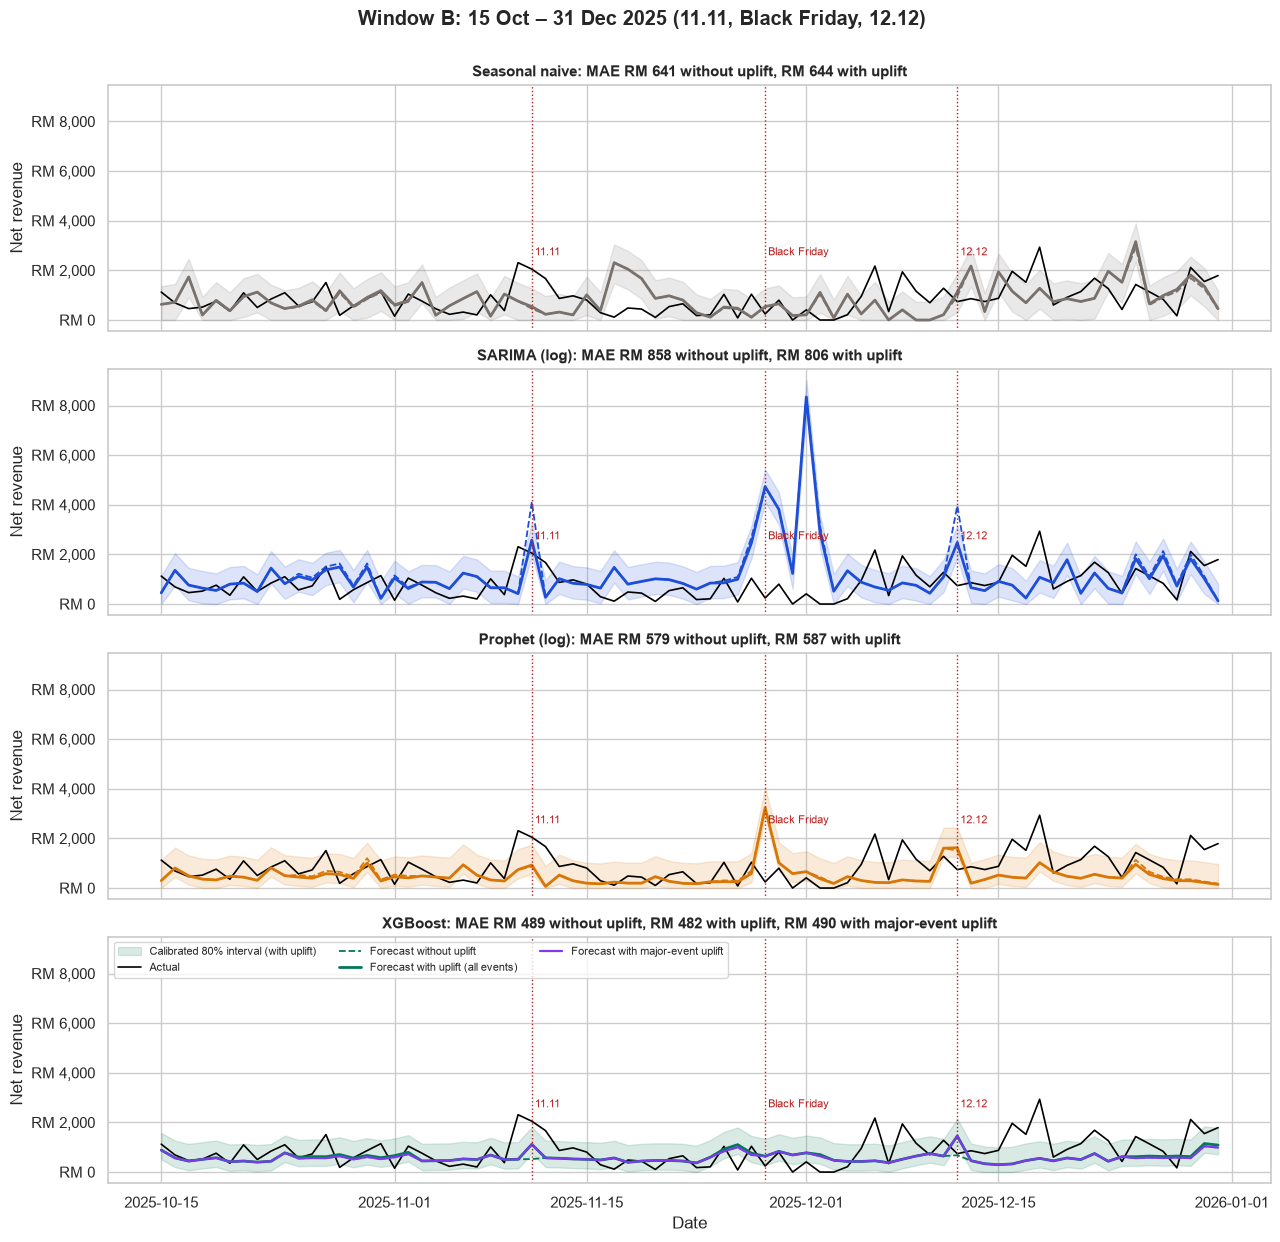

In [10]:
def forecast_panels(key, filename):
    window = runs[runs["window"] == key]
    names = [m.name for m in base_models(key)]
    fig, axes = plt.subplots(len(names), 1, figsize=(13, 3.1 * len(names)), sharex=True, sharey=True)
    for ax, name in zip(axes, names):
        plain = window[window["model"] == name].set_index("date")
        lifted = window[window["model"] == name + " + uplift"].set_index("date")
        ax.fill_between(lifted.index, lifted["lower"], lifted["upper"], color=COLORS[name], alpha=0.15, label="Calibrated 80% interval (with uplift)")
        ax.plot(plain.index, plain["actual"], color="black", lw=1.2, label="Actual")
        ax.plot(plain.index, plain["yhat"], color=COLORS[name], lw=1.3, ls="--", label="Forecast without uplift")
        ax.plot(lifted.index, lifted["yhat"], color=COLORS[name], lw=2, label="Forecast with uplift (all events)")
        major = window[window["model"] == name + " + major-event uplift"].set_index("date")
        if len(major):
            ax.plot(major.index, major["yhat"], color="#7c3aed", lw=1.6, label="Forecast with major-event uplift")
        for day, label in event_labels(plain.index).items():
            if label in ("9.9", "10.10", "11.11", "12.12") or (label == "black_friday" and day.dayofweek == 4):
                ax.axvline(day, color="#b91c1c", ls=":", lw=1)
                ax.text(day, plain["actual"].max(), " " + ("Black Friday" if label == "black_friday" else label), fontsize=8, color="#b91c1c", va="top")
        mae_plain = results[(results["window"] == key) & (results["model"] == name)]["MAE (RM)"].iloc[0]
        mae_up = results[(results["window"] == key) & (results["model"] == name + " + uplift")]["MAE (RM)"].iloc[0]
        title = f"{name}: MAE RM {mae_plain:,.0f} without uplift, RM {mae_up:,.0f} with uplift"
        if len(major):
            mae_major = results[(results["window"] == key) & (results["model"] == name + " + major-event uplift")]["MAE (RM)"].iloc[0]
            title += f", RM {mae_major:,.0f} with major-event uplift"
        ax.set_title(title, fontsize=11)
        ax.set_ylabel("Net revenue")
        rm_axis(ax)
    axes[-1].legend(loc="upper left", ncol=3, fontsize=8)
    axes[-1].set_xlabel("Date")
    fig.suptitle(WINDOWS[key]["label"], fontweight="bold", y=1.0)
    fig.tight_layout()
    save(fig, filename)
    plt.show()


forecast_panels("B", "04b_window_b_events.png")

**Finding:** On the 2025 event days, the major-event version lifts **11.11** from RM 523 to RM 1,118 (actual RM 2,050): still too low, but much closer. It also lifts **12.12** from RM 679 to RM 1,451, about twice the actual RM 740 (see the recheck below). Black Friday is unchanged in window B (RM 639, actual RM 245), because the training data before 15 Oct 2025 holds no Black Friday that can be forecast out of sample, so its multiplier stayed at 1. The log models are dangerous around events: SARIMA forecast RM 4,119 for 11.11, RM 4,731 for Black Friday and about RM 8,300 on 1 Dec, and Prophet RM 3,237 for Black Friday. On the log scale an event effect learned from one example becomes a huge multiplier.

saved 04b_window_a_forecasts.png


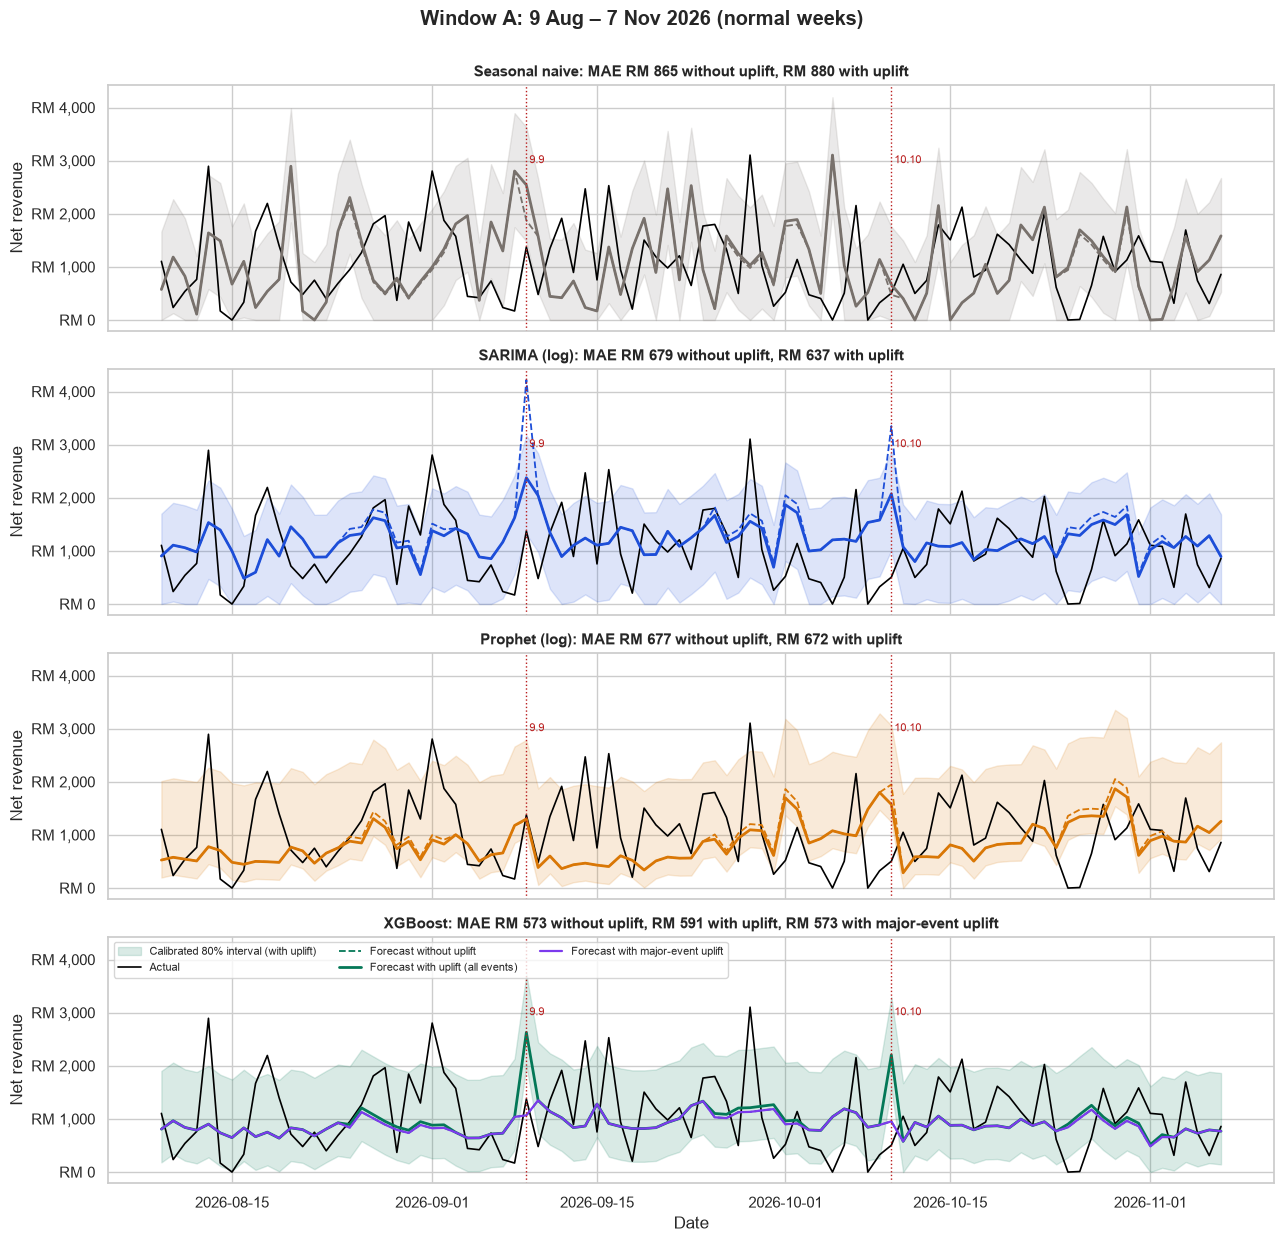

In [11]:
forecast_panels("A", "04b_window_a_forecasts.png")

**Finding:** Window A has no major event, so the major-event version is the same as plain XGBoost there. The all-events uplift adds 7–10% on payday days and lifts 9.9 and 10.10, which were weak in 2026 (RM 1,375 and RM 505). That's why the all-events version is worse in window A, and why leaving the small events to XGBoost's own calendar features costs nothing. SARIMA (log) runs above the actual level for most of the window (+34% weekly bias), and Prophet (log) is close to centred (−6%) but noisy.

## 6. v1 vs v2
Window A is the same 91 days as v1, so the numbers can be compared directly. For XGBoost, v2 is the **final model** (XGBoost + major-event uplift);
for the other models, the version (with or without uplift) with the lower mean MAE over both windows. v1's coverage is the model's own interval;
v2's is the calibrated one.

,v2 version,MAE v1,MAE v2,weekly error v1,weekly error v2,weekly bias v1,weekly bias v2,coverage v1,coverage v2
model,,,,,,,,,
Seasonal naive,Seasonal naive,RM 875,RM 865,35.2%,29.4%,+11.3%,+7.2%,63.7%,72.5%
SARIMA (log),SARIMA (log) + uplift,RM 643,RM 637,36.4%,36.2%,+24.4%,+25.3%,63.7%,75.8%
Prophet (log),Prophet (log),RM 647,RM 677,40.9%,45.5%,+26.1%,-6.4%,58.2%,62.6%
XGBoost,XGBoost + major-event uplift,RM 587,RM 573,27.0%,25.0%,-3.6%,-9.0%,64.8%,78.0%


saved 04b_v1_vs_v2.png


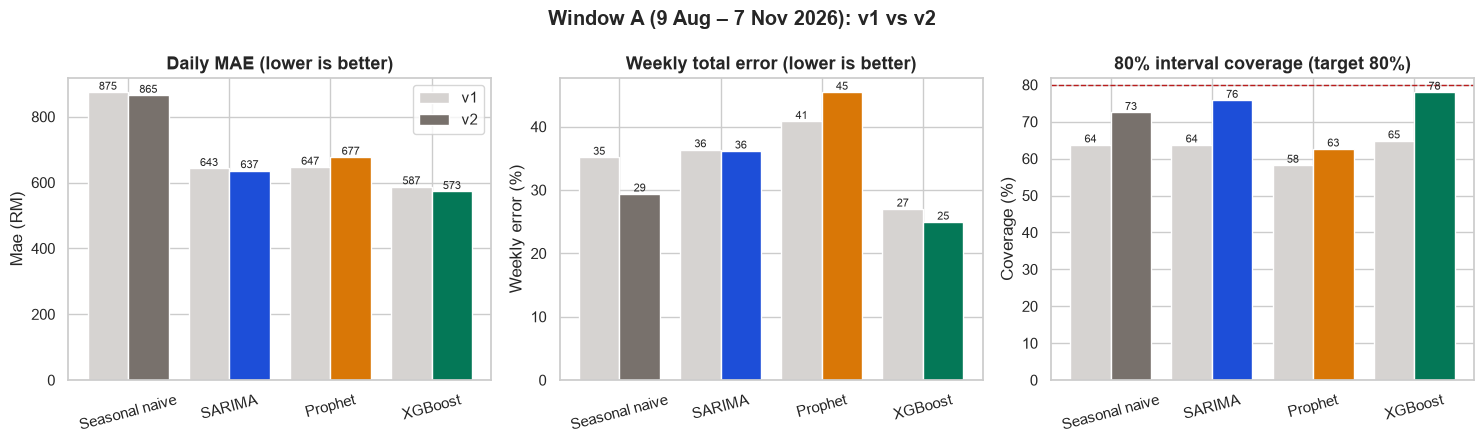

In [12]:
v1 = pd.read_csv(REPORT_DIR / "revenue_model_comparison_v1.csv").set_index("model")
V1_NAME = {"Seasonal naive": "Seasonal naive", "SARIMA (log)": "SARIMA", "Prophet (log)": "Prophet", "XGBoost": "XGBoost"}
rows = []
for base in V1_NAME:
    variant = "XGBoost + major-event uplift" if base == "XGBoost" else min([base, base + " + uplift"], key=lambda m: ranking.loc[m, "mean MAE (RM)"])
    v2 = results[(results["window"] == "A") & (results["model"] == variant)].iloc[0]
    old = v1.loc[V1_NAME[base]]
    rows.append({"model": base, "v2 version": variant,
                 "MAE v1": old["MAE (RM)"], "MAE v2": v2["MAE (RM)"],
                 "weekly error v1": old["weekly total error (%)"], "weekly error v2": v2["weekly total error (%)"],
                 "weekly bias v1": old["weekly total bias (%)"], "weekly bias v2": v2["weekly total bias (%)"],
                 "coverage v1": old["80% interval coverage (%)"], "coverage v2": v2["80% interval coverage (%)"]})
compare = pd.DataFrame(rows).set_index("model")
display(compare.style.format({c: ("RM {:,.0f}" if c.startswith("MAE") else "{:+.1f}%" if "bias" in c else "{:.1f}%") for c in compare.columns if c != "v2 version"}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
x = np.arange(len(compare))
for ax, (metric, title, unit) in zip(axes, [("MAE", "Daily MAE (lower is better)", "RM"), ("weekly error", "Weekly total error (lower is better)", "%"),
                                           ("coverage", "80% interval coverage (target 80%)", "%")]):
    ax.bar(x - 0.2, compare[f"{metric} v1"], 0.4, color="#d6d3d1", label="v1")
    ax.bar(x + 0.2, compare[f"{metric} v2"], 0.4, color=[COLORS[m] for m in compare.index], label="v2")
    for i, (a, b) in enumerate(zip(compare[f"{metric} v1"], compare[f"{metric} v2"])):
        ax.text(i - 0.2, a, f"{a:,.0f}", ha="center", va="bottom", fontsize=8)
        ax.text(i + 0.2, b, f"{b:,.0f}", ha="center", va="bottom", fontsize=8)
    if metric == "coverage":
        ax.axhline(80, color="#b91c1c", ls="--", lw=1)
    ax.set_xticks(x, [m.replace(" (log)", "") for m in compare.index], rotation=15)
    ax.set(title=title, ylabel=f"{metric.capitalize()} ({unit})")
axes[0].legend()
fig.suptitle("Window A (9 Aug – 7 Nov 2026): v1 vs v2", fontweight="bold")
fig.tight_layout()
save(fig, "04b_v1_vs_v2.png")
plt.show()

**Like-for-like note (9 Nov 2026):** the v1 figures in the table and chart above were calculated before the 9 seeded orders were corrected, and the v2 figures after. So the drop for XGBoost (RM 587 → RM 573) comes from the **data correction, not the model**; compare v2 with v1 only on the same data. The rest of this finding uses the figures from before the correction, where both versions saw the same data (v2 XGBoost + major-event uplift: RM 587.16; v1 XGBoost: RM 587.44).

**Finding:** In window A (the same days as v1), v2 **did not improve accuracy**. The final XGBoost + major-event uplift is unchanged from v1 (MAE RM 587, weekly error 27%), SARIMA is slightly worse (RM 643 → 661) and Prophet is worse (RM 647 → 701). The clear gains are **bias and intervals**: Prophet's weekly bias went from +26% to +0.3%, and the calibrated intervals now cover 63–75% instead of 58–65%, with XGBoost closest to the 80% target. For the report: the v2 changes fixed the specific faults found in v1 (degenerate SARIMA, Prophet's over-forecast, narrow intervals) and added visible event days at no cost in normal weeks, but the extra complexity didn't beat a well-built XGBoost on daily accuracy.

## 7. Final model: XGBoost + major-event uplift

**Decision and why.** The final model is **XGBoost with the event uplift applied only to major campaign events: 11.11, 12.12, Black Friday,
the pre-Raya window and the Raya closure**. Smaller events (payday, 9.9, 10.10, CNY, Deepavali, back-to-school) get no uplift: XGBoost's own
calendar features already handle them.

This is a **business decision, not tuning on the test windows**. The admin uses the forecast to plan stock, staff and cash around the big sales
days, so the forecast must *show* those days, even if that costs a little average accuracy. Plain XGBoost has the lowest mean MAE (section 5),
but it forecasts 11.11 as a normal day, which is the one day the admin most needs to see. The list of major events was fixed from the shop's
calendar (its biggest campaigns and the Raya season), not chosen by trying event combinations on windows A and B. The multipliers are estimated
exactly as for the all-events version, from training data only, and section 5 shows this version's scores on both windows next to the plain model,
so the cost is visible.

The model is retrained on **all 737 days**. The saved object is an `EventAdjusted` wrapper: it learns the multipliers and interval widths from all
the data, then forecasts with them.

In [13]:
base_name, use_uplift = "XGBoost", True
FINAL_VARIANT = "XGBoost + major-event uplift"
final = EventAdjusted(XGBoostModel(), uplift=True, events=MAJOR_EVENTS).fit(y)
display(final.multipliers_.assign(applied=final.multipliers_.index.isin(MAJOR_EVENTS)).round(2).rename_axis("estimated on all data"))

future = pd.date_range(y.index.max() + pd.Timedelta(days=1), periods=30, freq="D")
forecast = final.predict(future)
plain_forecast = final.base_.predict(future)

next7 = forecast.iloc[:7].copy()
next7.insert(0, "day", next7.index.day_name().str[:3])
next7.insert(1, "event", event_labels(next7.index).fillna("").replace({"black_friday": "Black Friday", "payday": "payday"}))
next7["multiplier"] = [final.applied_multipliers_.get(e, 1.0) if isinstance(e, str) else 1.0 for e in event_labels(next7.index)]
next7["without uplift"] = plain_forecast["yhat"].iloc[:7]
week_total = next7["yhat"].sum()
low, high = final.weekly_range(week_total)
print(f"Final model: {final.name} (trained until {final.trained_until_:%d %b %Y})")
print(f"Next 7 days: RM {week_total:,.0f} (80% range RM {low:,.0f} – {high:,.0f}) · last 7 days actual RM {y.iloc[-7:].sum():,.0f}")
print("Multipliers applied:", ", ".join(f"{k} x{v:.2f}" for k, v in final.applied_multipliers_.items()))
next7.style.format({"yhat": "RM {:,.0f}", "lower": "RM {:,.0f}", "upper": "RM {:,.0f}", "without uplift": "RM {:,.0f}", "multiplier": "x{:.2f}"})

,occurrences,days,raw ratio,prior,multiplier,applied
estimated on all data,,,,,,
9.9,2,2,1.55,1.44,1.49,False
10.10,2,2,1.42,1.44,1.43,False
11.11,1,1,3.20,1.44,2.02,True
12.12,1,1,0.80,1.44,1.22,True
black_friday,1,4,0.38,1.00,0.79,True
raya_closure,2,8,0.63,1.00,0.82,True
pre_raya,2,42,1.18,1.00,1.09,True
chinese_new_year,2,4,1.35,1.00,1.17,False
payday,23,166,1.11,1.00,1.10,False


Final model: XGBoost + major-event uplift (trained until 07 Nov 2026)
Next 7 days: RM 6,398 (80% range RM 4,916 – 11,336) · last 7 days actual RM 6,110
Multipliers applied: 11.11 x2.02, 12.12 x1.22, black_friday x0.79, raya_closure x0.82, pre_raya x1.09


,day,event,yhat,lower,upper,multiplier,without uplift
2026-11-08 00:00:00,Sun,,RM 769,RM 157,"RM 1,867",x1.00,RM 769
2026-11-09 00:00:00,Mon,,RM 687,RM 74,"RM 1,785",x1.00,RM 687
2026-11-10 00:00:00,Tue,,RM 644,RM 31,"RM 1,742",x1.00,RM 644
2026-11-11 00:00:00,Wed,11.11,"RM 1,798","RM 1,185","RM 2,896",x2.02,RM 888
2026-11-12 00:00:00,Thu,,RM 795,RM 182,"RM 1,893",x1.00,RM 795
2026-11-13 00:00:00,Fri,,RM 751,RM 138,"RM 1,849",x1.00,RM 751
2026-11-14 00:00:00,Sat,,RM 954,RM 341,"RM 2,051",x1.00,RM 954


saved 04b_next_30_days_forecast_v2.png


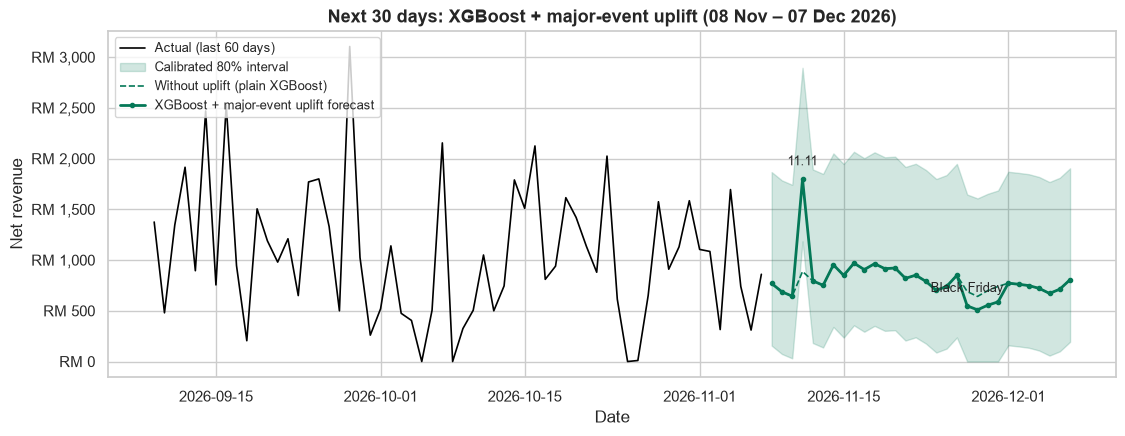

In [14]:
recent = y[y.index > y.index.max() - pd.Timedelta(days=60)]
color = COLORS[base_name]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(recent.index, recent.values, color="black", lw=1.2, label="Actual (last 60 days)")
ax.fill_between(forecast.index, forecast["lower"], forecast["upper"], color=color, alpha=0.18, label="Calibrated 80% interval")
if use_uplift:
    ax.plot(plain_forecast.index, plain_forecast["yhat"], color=color, lw=1.2, ls="--", label="Without uplift (plain XGBoost)")
ax.plot(forecast.index, forecast["yhat"], color=color, lw=2, marker="o", ms=3, label=f"{final.name} forecast")
for day, label in event_labels(forecast.index).items():
    if label in ("11.11", "12.12") or (label == "black_friday" and day.dayofweek == 4):
        ax.annotate("Black Friday" if label == "black_friday" else label, (day, forecast.loc[day, "yhat"]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
ax.set(title=f"Next 30 days: {final.name} ({future[0]:%d %b} – {future[-1]:%d %b %Y})", xlabel="Date", ylabel="Net revenue")
rm_axis(ax)
ax.legend(loc="upper left", fontsize=9)
save(fig, "04b_next_30_days_forecast_v2.png")
plt.show()

**Finding:** The final model, **XGBoost + major-event uplift**, forecasts **RM 6,398 for 8–14 Nov 2026** (80% range RM 4,916 – 11,336), with **11.11 at RM 1,798** (range RM 1,185 – 2,896; ×2.02 on the plain forecast of RM 888). Last week's actual was RM 6,110, and past 11.11s were RM 1,640 (2024) and RM 2,050 (2025). The other six days are the same as plain XGBoost (about RM 640–950). On all data the multipliers applied are 11.11 ×2.02, 12.12 ×1.22, pre-Raya ×1.09, Raya closure ×0.82 and Black Friday ×0.79. 12.12's own example was 0.80×; it reaches 1.22 because, with a single example, it is shrunk toward the shared double-day value.

### Alternative (not chosen): XGBoost + uplift on all events
For comparison only: the same XGBoost with the uplift on **all** event types (also payday, 9.9, 10.10 and CNY), trained on all data.

In [15]:
alternative = EventAdjusted(XGBoostModel(), uplift=True).fit(y)
alt7 = alternative.predict(future[:7])
alt7.insert(0, "day", alt7.index.day_name().str[:3])
alt_total = alt7["yhat"].sum()
alt_low, alt_high = alternative.weekly_range(alt_total)
print(f"XGBoost + uplift (all events), next 7 days: RM {alt_total:,.0f} (80% range RM {alt_low:,.0f} – {alt_high:,.0f}) · 11.11 multiplier ×{alternative.multipliers_.loc['11.11', 'multiplier']:.2f}")
alt7.style.format({"yhat": "RM {:,.0f}", "lower": "RM {:,.0f}", "upper": "RM {:,.0f}"})

XGBoost + uplift (all events), next 7 days: RM 6,398 (80% range RM 4,902 – 10,598) · 11.11 multiplier ×2.02


,day,yhat,lower,upper
2026-11-08 00:00:00,Sun,RM 769,RM 123,"RM 1,824"
2026-11-09 00:00:00,Mon,RM 687,RM 40,"RM 1,742"
2026-11-10 00:00:00,Tue,RM 644,RM 0,"RM 1,699"
2026-11-11 00:00:00,Wed,"RM 1,798","RM 1,151","RM 2,852"
2026-11-12 00:00:00,Thu,RM 795,RM 148,"RM 1,850"
2026-11-13 00:00:00,Fri,RM 751,RM 105,"RM 1,806"
2026-11-14 00:00:00,Sat,RM 954,RM 307,"RM 2,008"


In [16]:
model_path = MODEL_DIR / "revenue_model.joblib"
joblib.dump(final, model_path)
best_rows = results[results["model"] == FINAL_VARIANT].set_index("window").drop(columns="model")
metadata = {
    "version": "v2",
    "model_name": final.name,
    "model_class": "forecasting.adjust.EventAdjusted",
    "base_model": f"forecasting.models.{type(final.base).__name__}",
    "base_settings": {"sarima_order": list(sarima_choice["A"][0]), "sarima_seasonal_order": list(sarima_choice["A"][1]),
                      "prophet_trend": prophet_choice["A"]},
    "event_uplift": "major campaign events only",
    "uplift_events": list(final.events),
    "event_multipliers_applied": {k: round(v, 3) for k, v in final.applied_multipliers_.items()},
    "event_multipliers_estimated_all": final.multipliers_["multiplier"].round(3).to_dict(),
    "interval": "calibrated 80% interval: 10th/90th percentile of inner-fold errors (last 182 days)",
    "interval_offsets": {k: round(v, 3) for k, v in final.offsets_.items()},
    "target": "daily net revenue (RM): paid orders (status paid/shipped/completed/refunded), dated by paid_at in Malaysia time (UTC+8), total - refunded_amount",
    "trained_from": f"{y.index.min():%Y-%m-%d}", "trained_until": f"{final.trained_until_:%Y-%m-%d}", "training_days": int(len(y)),
    "features": list(final.features),
    "selection": ("business decision: XGBoost (lowest mean MAE of the base models over two rolling-origin test windows) with the event uplift "
                  "applied only to major campaign events (11.11, 12.12, Black Friday, pre-Raya, Raya closure), so the admin sees the big sales days. "
                  "The event list was fixed from the shop calendar, not tuned on the test windows. Plain XGBoost had the lowest mean MAE."),
    "plain_xgboost_metrics": {key: {k: round(float(v), 2) for k, v in results[(results["model"] == "XGBoost") & (results["window"] == key)]
                                    .drop(columns=["window", "model"]).iloc[0].items()} for key in WINDOWS},
    "evaluation": {key: {"window": WINDOWS[key]["label"], "from": f"{WINDOWS[key]['start']:%Y-%m-%d}", "until": f"{WINDOWS[key]['end']:%Y-%m-%d}",
                         "metrics": {k: round(float(v), 2) for k, v in best_rows.loc[key].items()}} for key in WINDOWS},
    "comparison_file": "reports/revenue_model_comparison.csv (v1: reports/revenue_model_comparison_v1.csv)",
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "evaluated_at": EVALUATED_AT.isoformat(timespec="seconds"),
    "evaluated_on_data_until": f"{y.index[-1]:%Y-%m-%d}",
    "versions": {p: version(p) for p in ["pandas", "numpy", "scikit-learn", "xgboost", "statsmodels", "prophet", "joblib"]},
    "load": "sys.path.insert(0, 'ml-service'); model = joblib.load('ml-service/models/revenue_model.joblib'); model.predict(dates); model.weekly_range(total)",
}
(MODEL_DIR / "revenue_model.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
reloaded = joblib.load(model_path)
assert np.allclose(reloaded.predict(future)["yhat"], forecast["yhat"])
print(f"saved {model_path.name} ({model_path.stat().st_size / 1024:,.0f} KB) + revenue_model.json · reload check passed")

saved revenue_model.joblib (1,393 KB) + revenue_model.json · reload check passed


## 8. Summary

- **Final model: XGBoost + major-event uplift** (11.11, 12.12, Black Friday, pre-Raya, Raya closure), saved as `models/revenue_model.joblib` with calibrated intervals. It's a business choice so the admin sees the big sales days. Its mean MAE ties plain XGBoost (RM 531), it is identical in normal weeks, and it slightly improves event-window weekly totals. v1 is kept as `revenue_model_v1.*`.
- **Next 7 days (8–14 Nov 2026):** RM 6,398 (range RM 4,916 – 11,336), with 11.11 at RM 1,798. Plain XGBoost would have said RM 888.
- **11.11 is still under-forecast** in the backtest (RM 1,118 vs RM 2,050 in 2025), because its multiplier rests on a single out-of-sample example. **12.12 is over-forecast** (RM 1,451 vs RM 740), because the data shows 12.12 is only a small lift (0.48× and 1.21×).
- **SARIMA on log scale** now uses real orders ((2,1,2)×(0,1,1,7) and (0,0,0)×(0,1,1,7)), but it is less accurate than v1 and over-reacts to events.
- **Prophet's over-forecast is fixed** by a flat trend (weekly bias in window A: +26% in v1, +0.3% in v2 on the same data, −6% after the data correction), but its daily error grew (RM 647 → 701 on the same data).
- **Calibrated intervals** bring XGBoost's coverage from 67% to 78% (window A), but event weeks still fall outside more often (about 65%).
- **For the dashboard:** show weekly totals with the calibrated range, and mark the major event days.